In [1]:
!pip install --upgrade binance-historical-data plotly backtrader -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 35.7 MB/s eta 0:00:00


In [2]:
import os
import warnings
import pandas as pd
import plotly.graph_objects as go
import backtrader as bt
import numpy as np
import statsmodels.api as sm
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper

from curl_cffi import requests # For robust yfinance downloads
session = requests.Session(impersonate="chrome") # Mimic browser
from sys import exit # For clean exit on data errors
import matplotlib.pyplot as plt
# %matplotlib qt5 # For interactive plots in IPython/Spyder, run this in your console

warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_list_all_trading_pairs()

def filter_usdt_tickers(tickers):
    exclude_keywords = ["UPUSDT", "DOWNUSDT", "BEARUSDT", "BULLUSDT"]
    return [ticker for ticker in tickers if ticker.endswith("USDT") and not any(ex in ticker for ex in exclude_keywords)]

def find_first_data_date(ticker):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_min_start_date_for_ticker(ticker)

def format_time(seconds):
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data

In [8]:
ticker = 'BTCUSDT'
data_frequency = '1d'
download_ticker(ticker, "2015-01-01", "2025-12-18", data_frequency)
data_ohlcv = process_csv_files(ticker, data_frequency)
data_ohlcv = data_ohlcv.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
data_ohlcv


---> Found overall tickers: 614
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1d
---> Start Date: 20170101
---> End Date: 20251218


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download:   0%|          | 0/4 [00:00<?, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 0 months 0 days
---> For BTCUSD new data saved for: 0 months 1 days


,open_time,Open,High,Low,Close,Volume
468,2017-08-18,4285.08,4371.52,3938.77,4108.37,1199.888264
469,2017-08-19,4108.37,4184.69,3850.00,4139.98,381.309763
470,2017-08-20,4120.98,4211.08,4032.62,4086.29,467.083022
471,2017-08-21,4069.13,4119.62,3911.79,4016.00,691.743060
472,2017-08-22,4016.00,4104.82,3400.00,4040.00,966.684858
...,...,...,...,...,...,...
1394,2025-11-26,87369.97,90656.08,86306.77,90484.02,21675.822390
1395,2025-11-27,90484.01,91950.00,90089.91,91333.95,16833.509320
1396,2025-11-28,91333.94,93092.00,90180.63,90890.70,18830.860120
1397,2025-11-29,90890.71,91165.65,90155.47,90802.44,7429.882910


In [4]:
df = data_ohlcv.copy()

# OHLC Chart
fig = go.Figure(
    data=[
        go.Candlestick(
            x=df["open_time"],
            open=df["Open"],
            high=df["High"],
            low=df["Low"],
            close=df["Close"],
            name="OHLC"
        )
    ]
)

# Layout config
fig.update_layout(
    title="OHLC Chart",
    xaxis_title="Time",
    yaxis_title="Price",
    xaxis_rangeslider_visible=False,
    template="plotly_dark",
    height=600
)

fig.show()

In [5]:
class StateSpaceTrendVolatility(bt.Strategy):
  params = (
        ('model_update_period', 60 * 24),    # Default: How often to re-fit the model (bars)
        ('lookback_period', 365 * 24),       # Default: Data window for model fitting (bars)
        ('trend_slope_threshold_buy', 0.0005), # Default: Min positive slope for buy
        ('trend_slope_threshold_sell', -0.0005),# Default: Max negative slope for sell
    )

  def __init__(self):
        self.btc_close = self.datas[0].close
        self.order = None
        self.model_fit_day = -self.p.model_update_period # Ensure model fits early
        self.trend_level = None
        self.trend_slope = None
        self.log_price_at_fit = None # For debugging model fit

  def log(self, txt, dt=None):
        dt = dt or self.datas[0].datetime.date(0)
        print(f'{dt.isoformat()} {txt}')

    # notify_order and notify_trade methods for logging (standard Backtrader)
  def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return
        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED, Price: {order.executed.price:.2f}, Cost: {order.executed.value:.2f}, Comm: {order.executed.comm:.2f}')
            elif order.issell():
                self.log(f'SELL EXECUTED, Price: {order.executed.price:.2f}, Cost: {order.executed.value:.2f}, Comm: {order.executed.comm:.2f}')
            # self.bar_executed = len(self) # Optional: track bar of execution
        elif order.status in [order.Canceled, order.Margin, order.Rejected]:
            self.log('Order Canceled/Margin/Rejected')
        self.order = None

  def notify_trade(self, trade):
        if not trade.isclosed:
            return
        self.log(f'OPERATION PROFIT, GROSS {trade.pnl:.2f}, NET {trade.pnlcomm:.2f}')

    # ... (fit_state_space_model and next methods discussed below) ...
  def fit_state_space_model(self):
        current_bar_index = len(self)
        if current_bar_index < self.p.lookback_period:
            self.log(f"Not enough data to fit model yet. Have {current_bar_index}, need {self.p.lookback_period}.")
            return False

        # Collect historical close prices for the lookback period
        dates = [bt.num2date(self.datas[0].datetime[-i]) for i in range(self.p.lookback_period - 1, -1, -1)]
        closes = [self.datas[0].close[-i] for i in range(self.p.lookback_period - 1, -1, -1)]

        ts_data = pd.Series(closes, index=pd.to_datetime(dates)).dropna()

        self.log(f"Fitting SSM: Data from {ts_data.index[0].date()} to {ts_data.index[-1].date()}, {len(ts_data)} points.")
        if ts_data.empty or (ts_data <= 0).any():
            self.log("ERROR: Data for model is empty or contains non-positive values.")
            return False

        try:
            log_ts_data = np.log(ts_data)
            self.log_price_at_fit = log_ts_data.iloc[-1]

            if log_ts_data.isnull().any() or np.isinf(log_ts_data).any():
                self.log("ERROR: log_ts_data contains NaN or Inf values!")
                return False

            # Define the Unobserved Components model: Local Linear Trend
            model = sm.tsa.UnobservedComponents(
                log_ts_data,
                level='lltrend',
                # irregular=True # Optional: add if residuals are white noise
            )

            with warnings.catch_warnings(): # Suppress common fitting warnings
                warnings.simplefilter("ignore")
                result = model.fit(method='lbfgs', disp=False, maxiter=500)

            self.log(f"DEBUG: Model converged: {result.mle_retvals['converged']}")
            self.log(f"DEBUG: Model log-likelihood: {result.llf:.4f}")

            filtered_state = result.filter_results.filtered_state

            if filtered_state.shape[1] >= 2: # Expecting at least level and slope
                self.trend_level = filtered_state[-1, 0]  # Last log-level
                self.trend_slope = filtered_state[-1, 1]  # Last log-slope
                self.log(f"Model Fit: Actual Last Log-Price: {self.log_price_at_fit:.4f}, Estimated Log-Trend Level: {self.trend_level:.4f}, Slope: {self.trend_slope:.4f}")

                # Sanity check for model fit
                if np.isclose(self.trend_level, 0.0, atol=1e-3) and not np.isclose(self.log_price_at_fit, 0.0, atol=1e-3):
                    self.log("WARNING: Estimated log-trend level is suspiciously close to zero. Check model fit quality.")

                if np.isnan(self.trend_level) or np.isnan(self.trend_slope):
                    self.log("ERROR: Trend level or slope is NaN after model fit.")
                    return False
                return True
            else:
                self.log(f"ERROR: Filtered state unexpected shape: {filtered_state.shape}")
                return False
        except Exception as e:
            self.log(f"ERROR fitting state-space model: {e}")
            import traceback
            self.log(traceback.format_exc())
            return False

  def next(self):
            # 🔴 DEBUG: Luôn in ở đầu để xác nhận hàm được gọi
        # if len(self) % 100 == 0:  # in ít thôi, tránh tràn log
        #     self.log(f"[DEBUG] next() called. Bar={len(self)}, Close={self.data.close[0]:.2f}")

        # Periodically re-fit the model
        if len(self) >= self.model_fit_day + self.p.model_update_period and \
           len(self) >= self.p.lookback_period:
            if self.fit_state_space_model():
                self.model_fit_day = len(self) # Update last fit day
            else:
                self.log("Model fitting failed. Holding off on trading.")
                # Consider closing open positions if model becomes unreliable
                return

        if self.order: # An order is pending, do nothing
            return

        if self.trend_level is None or self.trend_slope is None:
            # Model not ready or failed, do nothing
            return

        current_position_size = self.getposition().size

        # Buy Signal Logic
        if self.trend_slope > self.p.trend_slope_threshold_buy:
            if current_position_size == 0: # Not in market
                self.log(f'BUY CREATE @ {self.btc_close[0]:.2f}, Slope: {self.trend_slope:.5f}, Est.LogLvl: {self.trend_level:.4f}')
                self.order = self.buy()
            elif current_position_size < 0: # Currently short
                self.log(f'COVER SHORT & CONSIDER BUY @ {self.btc_close[0]:.2f}, Slope: {self.trend_slope:.5f}')
                self.order = self.close() # Close short position
                                          # Buy will be re-evaluated on next bar if signal persists

        # Sell Signal Logic
        elif self.trend_slope < self.p.trend_slope_threshold_sell:
            if current_position_size == 0: # Not in market
                self.log(f'SELL CREATE (SHORT) @ {self.btc_close[0]:.2f}, Slope: {self.trend_slope:.5f}, Est.LogLvl: {self.trend_level:.4f}')
                self.order = self.sell()
            elif current_position_size > 0: # Currently long
                self.log(f'LIQUIDATE LONG & CONSIDER SHORT @ {self.btc_close[0]:.2f}, Slope: {self.trend_slope:.5f}')
                self.order = self.close() # Close long position
                                          # Short will be re-evaluated on next bar
        else: # Optional: Neutral zone - close positions if slope flattens
            if current_position_size != 0:
                self.order = self.close()


class TestStrategy(bt.Strategy):
    def log(self, txt, dt=None):
        dt = dt or self.datas[0].datetime.date(0)
        print(f'{dt.isoformat()} {txt}')

    def next(self):
        self.log(f"TEST: Bar {len(self)}, Close={self.data.close[0]}")

✅ Kiểu index: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
📅 3 mốc thời gian đầu: [Timestamp('2017-08-18 00:00:00'), Timestamp('2017-08-19 00:00:00'), Timestamp('2017-08-20 00:00:00')]
📈 Shape: (2928, 5)
Starting Portfolio Value: 100000.00
2018-08-29 Fitting SSM: Data from 2017-08-18 to 2018-08-29, 365 points.
2018-08-29 DEBUG: Model converged: True
2018-08-29 DEBUG: Model log-likelihood: 550.5482
2018-08-29 Model Fit: Actual Last Log-Price: 8.8581, Estimated Log-Trend Level: 0.0000, Slope: 0.0077
2018-08-29 WARNING: Estimated log-trend level is suspiciously close to zero. Check model fit quality.
2018-08-29 BUY CREATE @ 7031.22, Slope: 0.00766, Est.LogLvl: 0.0000
2018-08-30 BUY EXECUTED, Price: 7033.21, Cost: 90025.47, Comm: 90.03
2018-11-30 Fitting SSM: Data from 2017-11-19 to 2018-11-30, 365 points.
2018-11-30 DEBUG: Model converged: True
2018-11-30 DEBUG: Model log-likelihood: 577.6393
2018-11-30 Model Fit: Actual Last Log-Price: 8.3043, Estimated Log-Trend Level: 0.0000, 

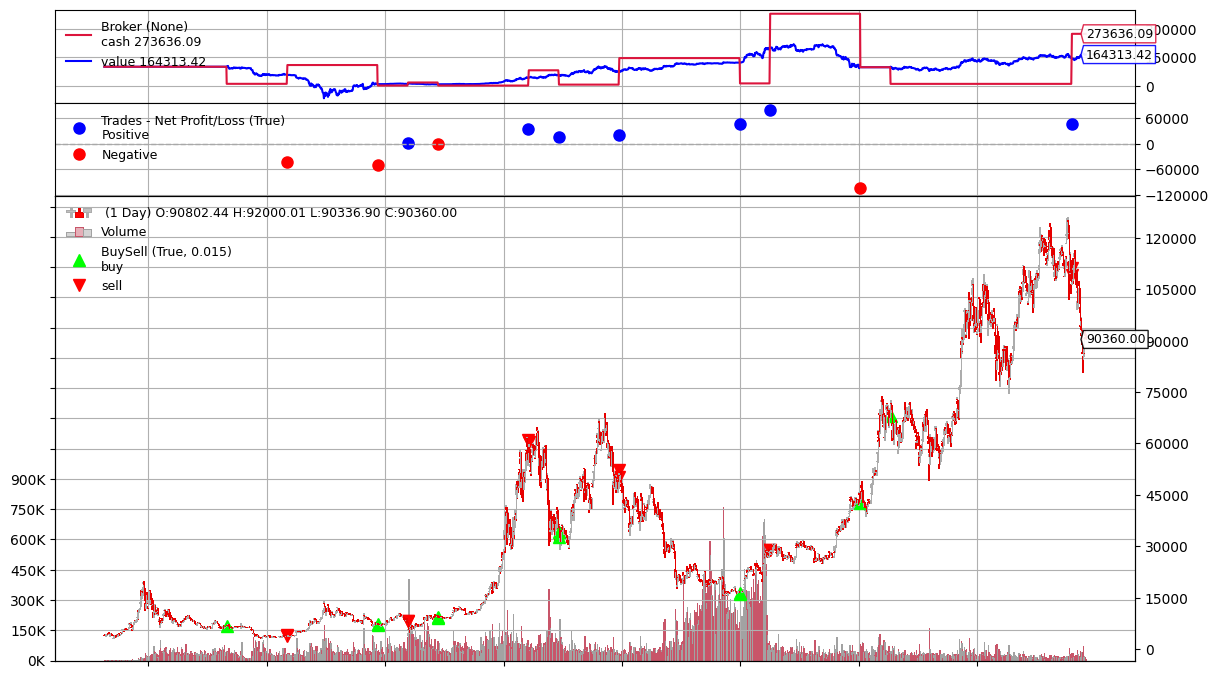

<Figure size 1200x700 with 0 Axes>

In [9]:
if __name__ == '__main__':
    cerebro = bt.Cerebro()

    # --- Data Feed Section ---
    data_df = data_ohlcv

    data_df['open_time'] = pd.to_datetime(data_df['open_time'], unit='ms')
    data_df.set_index('open_time', inplace=True)
    data_df.sort_index(inplace=True)

    # print(data_df.head())
    # print(data_df.tail())

    print("✅ Kiểu index:", type(data_df.index))
    print("📅 3 mốc thời gian đầu:", data_df.index[:3].tolist())
    print("📈 Shape:", data_df.shape)

    rename_map = { # Standardize to lowercase for Backtrader
        'Open': 'open', 'High': 'high', 'Low': 'low', 'Close': 'close', 'Volume': 'volume'
    }
    data_df.rename(columns=rename_map, inplace=True)
    for col in ['open', 'high', 'low', 'close', 'volume']: # Check essential columns
        if col not in data_df.columns:
            raise ValueError(f"Missing required column '{col}'. Columns are: {data_df.columns}")
    data_df['openinterest'] = 0 # Required by Backtrader
    data_df.index = pd.to_datetime(data_df.index)

    data = bt.feeds.PandasData(dataname=data_df)

    cerebro.adddata(data)

    # Add Strategy with tuned parameters (example values)
    cerebro.addstrategy(StateSpaceTrendVolatility,
                        model_update_period=90,  # Refit every ~3 months
                        lookback_period=365,     # Use 1 year of data for fitting
                        trend_slope_threshold_buy=0.001, # Stricter buy threshold
                        trend_slope_threshold_sell=-0.001)# Stricter sell threshold

    # cerebro.addstrategy(TestStrategy)

    # Broker, Sizer, Analyzers
    cerebro.broker.setcash(100000.0)
    cerebro.broker.setcommission(commission=0.001) # 0.1%
    cerebro.addsizer(bt.sizers.PercentSizer, percents=90) # Use 90% of cash

    cerebro.addanalyzer(bt.analyzers.SharpeRatio, _name='sharpe_ratio', timeframe=bt.TimeFrame.Minutes, compression=60, annualize=True, riskfreerate=0.03)
    cerebro.addanalyzer(bt.analyzers.AnnualReturn, _name='annual_return')
    cerebro.addanalyzer(bt.analyzers.DrawDown, _name='drawdown')
    cerebro.addanalyzer(bt.analyzers.TradeAnalyzer, _name='trade_analyzer')

    print('Starting Portfolio Value: %.2f' % cerebro.broker.getvalue())
    results = cerebro.run() # Optimization can be run with cerebro.optstrategy
    print('Final Portfolio Value: %.2f' % cerebro.broker.getvalue())

    # Print Analysis (with safer dictionary access)
    strat = results[0] # Assuming single strategy run
    print(f"\n--- Strategy Analysis ---")
    # ... (Detailed analyzer printout as in your provided script) ...
    # (Example for Sharpe)
    sharpe_analysis = strat.analyzers.sharpe_ratio.get_analysis()
    print(f"Sharpe Ratio: {sharpe_analysis.get('sharperatio', 'N/A'):.2f}")


    # Plotting
    plt.rcParams['figure.figsize'] = [12, 7] # Adjust figure size
    # For Spyder/IPython with Qt5 backend, ensure '%matplotlib qt5' was run in console
    cerebro.plot(iplot=False, style='candlestick')
    plt.tight_layout()
    # plt.show() # May be needed depending on environment

In [12]:
# --- Collect analyzer results ---
sharpe = strat.analyzers.sharpe_ratio.get_analysis()
annual = strat.analyzers.annual_return.get_analysis()
dd = strat.analyzers.drawdown.get_analysis()
trades = strat.analyzers.trade_analyzer.get_analysis()

total_trades = trades.total.total if 'total' in trades and 'total' in trades.total else 0
won = trades.won.total if 'won' in trades and 'total' in trades.won else 0
lost = trades.lost.total if 'lost' in trades and 'total' in trades.lost else 0

gross_profit = trades.won.pnl.total if won > 0 else 0
gross_loss = abs(trades.lost.pnl.total) if lost > 0 else 0

profit_factor = gross_profit / gross_loss if gross_loss > 0 else float('inf')

summary = {
    "Sharpe Ratio": sharpe.get("sharperatio", 0),
    "\Max Drawdown (%)": dd.max.drawdown,
    "Max Money DD": dd.max.moneydown,
    "Total Trades": total_trades,
    "Win Rate (%)": (won / total_trades * 100) if total_trades > 0 else 0,
    "Avg Win": trades.won.pnl.average if won > 0 else 0,
    "Avg Loss": trades.lost.pnl.average if lost > 0 else 0,
    "Profit Factor": profit_factor,
}

print(summary)

{'Sharpe Ratio': -0.030770581445072834, '\n Max Drawdown (%)': 163.73920815416568, 'Max Money DD': 170421.19618281044, 'Total Trades': 12, 'Win Rate (%)': 58.333333333333336, 'Avg Win': 34228.88657792766, 'Avg Loss': -48878.737887354844, 'Profit Factor': 1.2254930078067738}
